# Planning use case — experiments

Experiments for the planning use case of *Estimating the Installed Capacity of
Aggregated Thermostatically Controlled Loads from Net Load and Temperature*.
Each step calls one function of `scripts/planning.py`. Step reports, expectations
and deviations are in `RESULTS_LOG.md`; figures go to `figures/planning/`.

Every step pickles its results under `results/planning/`. With its `REBUILD_*`
flag at `False`, a step reloads them instead of recomputing.

In [1]:
import os, sys
_root = os.getcwd()
while not os.path.isdir(os.path.join(_root, 'paper')) and os.path.dirname(_root) != _root:
    _root = os.path.dirname(_root)
os.chdir(_root)
for _p in ('scripts', 'src'):
    if os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))

import pandas as pd
import planning as PL
pd.set_option('display.width', 200)

# control flags: True recomputes the step and overwrites its pickles
REBUILD_STEP0 = False
REBUILD_STEP1 = False   # True rescans ~1700 raw Swiss meter files (about 2 min)
print('repo root:', _root)

repo root: C:\Users\VENANCIA\OneDrive - VITO\Desktop\hp-sensitivity-paper


## Step 0 — Reproduce the baseline

Rebuilds the published 20-split Kloten design (seed 0, 1260 aggregates, target
aggregates drawn from all 1307 households without an HP) and checks every draft
number against its tolerance.

In [2]:
checks, step0 = PL.reproduce_baseline(rebuild=REBUILD_STEP0)
print('rebuilt design identical to the paper cache:', step0['same_as_paper_cache'])
checks

rebuilt design identical to the paper cache: True


,quantity,draft,reproduced,tol,ok
0,wape_i,19.3000,19.345896,0.5000,True
1,wape_i_le15,57.5000,57.466024,0.5000,True
2,wape_i_15_35,26.3000,26.288055,0.5000,True
3,wape_i_35_65,17.0000,17.042102,0.5000,True
4,wape_i_gt65,14.2000,14.220717,0.5000,True
5,wape_ii,14.5000,14.513574,0.5000,True
6,wape_iv,21.1000,21.075564,0.5000,True
7,median_over_pct,16.0000,15.901290,0.5000,True
8,mae_kw,17.0000,16.757828,0.5000,True
9,mean_hp_kw,6.3000,6.297227,0.0500,True


## Step 1 — Inventory of the data

1.1 completeness per winter (raw Swiss files; HEAPO from the kept daily coverage),
1.2 PV flags, 1.3 blocking periods of the 50 Kloten HPs, 1.4 nameplate ratings,
1.5 household structure of the real aggregates.

In [3]:
inv = PL.step1_inventory(rebuild=REBUILD_STEP1)
PL.years_table(inv['years'])

source       heapo     swiss    
role          free  hp  free  hp
W2019/20         0   0     0   0
W2020/21         0   0     0   0
W2021/22         0   4     0   0
W2022/23         1  22     0   0
W2023/24         0   0  1216  22
W2024/25         0   0     0   0
cal2023 heat     0  22  1226  23
cal2024 heat     0   0  1177  22

In [4]:
inv['pv'].groupby(['source', 'role']).agg(n=('pv_flag', 'size'), pv=('pv_flag', 'sum'))

n  pv
source role          
heapo  free     1   1
       hp      26  25
swiss  free  1306  15
       hp      24   1

cold days 19 | cold weekdays 13


figures\planning\fig_step1_blocking
HPs off 11:00-12:00 on >= 80 % of cold weekdays: 34 of 50


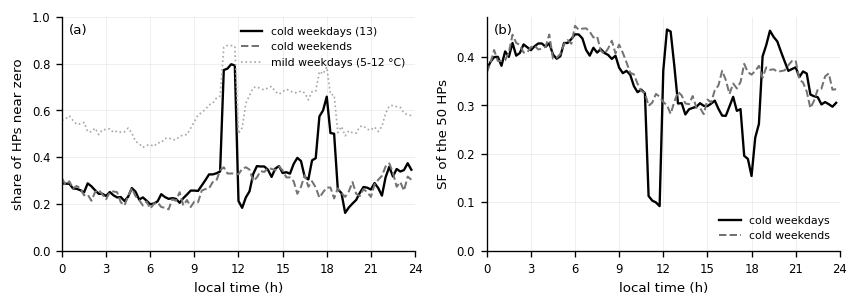

In [5]:
B = inv['blocking']
print('cold days', B['n_cold'], '| cold weekdays', B['n_cold_wkd'])
print(PL.fig_blocking(B))
blocked_11 = [h for h, r in inv['windows'].items() if any(a <= 44 and b >= 48 for a, b in r)]
print('HPs off 11:00-12:00 on >= 80 % of cold weekdays:', len(blocked_11), 'of', len(inv['windows']))

In [6]:
display(inv['nameplate']); inv['real']

,station,n_hp,heapo,with_protocol,HeatingCapacity,ElectricPower,HeatingPower
0,KLO,50,26,1,1,0,0
1,Hg,21,21,6,4,1,1
2,MqO,6,6,3,2,0,0


,aggregate,n_hp_households,hp_series,other_load_series,non_hp_households,non_hp_without_eheat,resolution
0,Hg,21,21,21,0,0,15 min
1,MqO,6,6,6,0,0,15 min
2,Hamelin (WPuQ),37,37,37,0,0,0 days 00:15:00
